# Task 5: Exploratory Data Analysis (EDA) — Titanic Dataset
**Objective:** Extract insights using visual and statistical exploration.  
**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn)  
**Dataset:** Titanic passenger data (891 passengers, 15 columns)

**Contents:** 1. Load & inspect · 2. Data quality · 3. Univariate · 4. Bivariate · 5. Multivariate · 6. Outliers & skewness · 7. Summary of findings · 8. Interview questions

## 1. Setup & Load Data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
os.makedirs('images', exist_ok=True)

df = pd.read_csv('titanic.csv')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Basic Inspection — `.info()`, `.describe()`, `.value_counts()`

In [2]:
print('Shape:', df.shape)
df.info()

Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [3]:
df.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


In [4]:
df.describe(include=['object','bool','category']).T

,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
adult_male,891,2,True,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549
alone,891,2,True,537


In [5]:
for col in ['survived','pclass','sex','embarked','who','alone']:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

--- survived ---
survived
0    549
1    342
Name: count, dtype: int64

--- pclass ---
pclass
3    491
1    216
2    184
Name: count, dtype: int64

--- sex ---
sex
male      577
female    314
Name: count, dtype: int64

--- embarked ---
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

--- who ---
who
man      537
woman    271
child     83
Name: count, dtype: int64

--- alone ---
alone
True     537
False    354
Name: count, dtype: int64



**Observations**
- 891 rows × 15 columns; only **38.4%** of passengers survived (342 of 891) → the target is moderately imbalanced.
- Mean age ≈ 29.7 yrs (min 0.42, max 80). Median fare is £14.45 but mean is £32.20 and max £512 → heavily **right-skewed** fare.
- 577 males vs 314 females; 491 passengers (55%) travelled 3rd class; 644 (72%) embarked at Southampton.

## 3. Data Quality — Missing Values & Duplicates

             missing   pct
age              177  19.9
embarked           2   0.2
deck             688  77.2
embark_town        2   0.2
Duplicate rows: 107


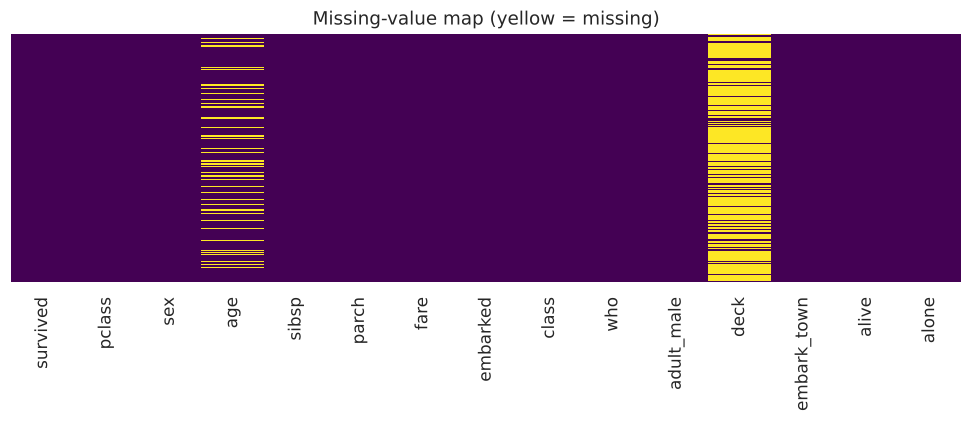

In [6]:
missing = df.isnull().sum().to_frame('missing')
missing['pct'] = (missing.missing/len(df)*100).round(1)
print(missing[missing.missing>0])
print('Duplicate rows:', df.duplicated().sum())

fig, ax = plt.subplots(figsize=(9,4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=ax)
ax.set_title('Missing-value map (yellow = missing)')
plt.tight_layout(); plt.savefig('images/01_missing.png'); plt.show()

**Observations**
- `deck` is missing for **688 rows (77%)** — mostly 2nd/3rd class passengers who had no cabin record; too sparse to impute, treat as "cabin known / unknown".
- `age` is missing for **177 rows (19.9%)** → impute with median (grouped by class/sex).
- `embarked` / `embark_town` have only 2 missing → fill with mode (Southampton).
- 107 duplicate rows exist, but with no passenger ID they are most likely different passengers with identical attributes (e.g., families) — they are kept.

In [7]:
# --- Cleaning ---
data = df.copy()
data['age'] = data.groupby(['pclass','sex'])['age'].transform(lambda s: s.fillna(s.median()))
data['embarked'] = data['embarked'].fillna(data['embarked'].mode()[0])
data['embark_town'] = data['embark_town'].fillna(data['embark_town'].mode()[0])
data['has_cabin'] = data['deck'].notna().astype(int)
data['family_size'] = data['sibsp'] + data['parch'] + 1
data['age_group'] = pd.cut(data['age'], [0,12,18,35,60,100], labels=['Child (0-12)','Teen (13-18)','Adult (19-35)','Middle (36-60)','Senior (60+)'])
print(data[['age','embarked']].isnull().sum())

age         0
embarked    0
dtype: int64


## 4. Univariate Analysis

### 4.1 Histograms — numeric variables

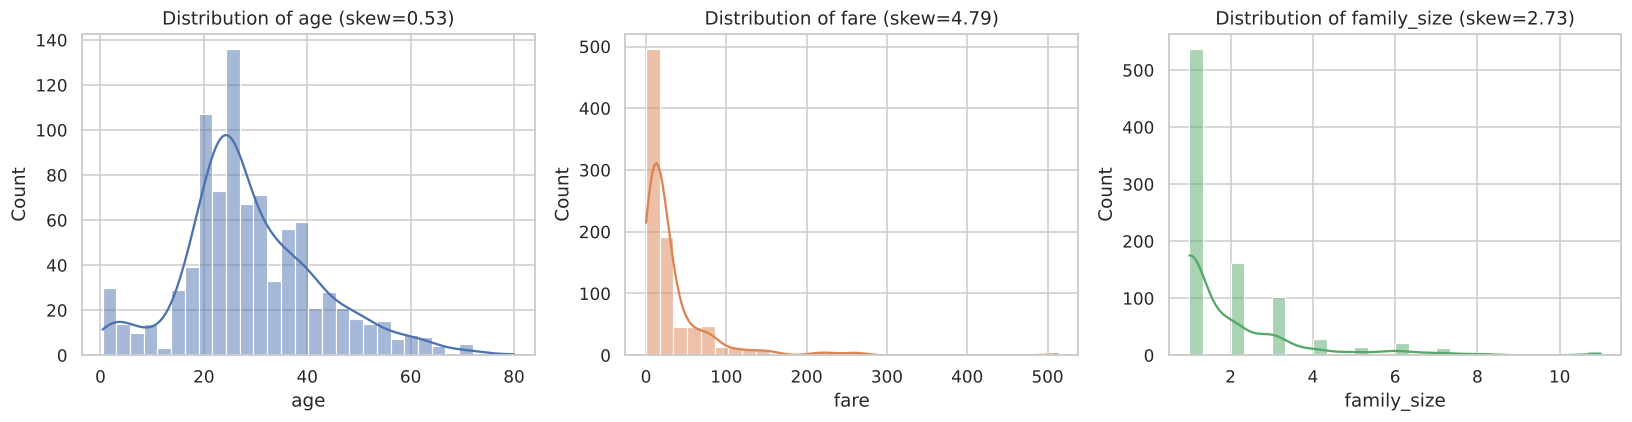

In [8]:
fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax,col,c in zip(axes,['age','fare','family_size'],['#4C72B0','#DD8452','#55A868']):
    sns.histplot(data[col], bins=30, kde=True, color=c, ax=ax)
    ax.set_title(f'Distribution of {col} (skew={data[col].skew():.2f})')
plt.tight_layout(); plt.savefig('images/02_histograms.png'); plt.show()

**Observations**
- **Age** is roughly bell-shaped (skew ≈ 0.4) with a peak at 20–30 and a small spike of infants (<5 yrs).
- **Fare** is extremely right-skewed (skew ≈ 4.8): most tickets are under £30, with a long tail up to £512.
- **Family size** is also right-skewed: 60% travelled alone; families of 5+ are rare.

### 4.2 Count plots — categorical variables

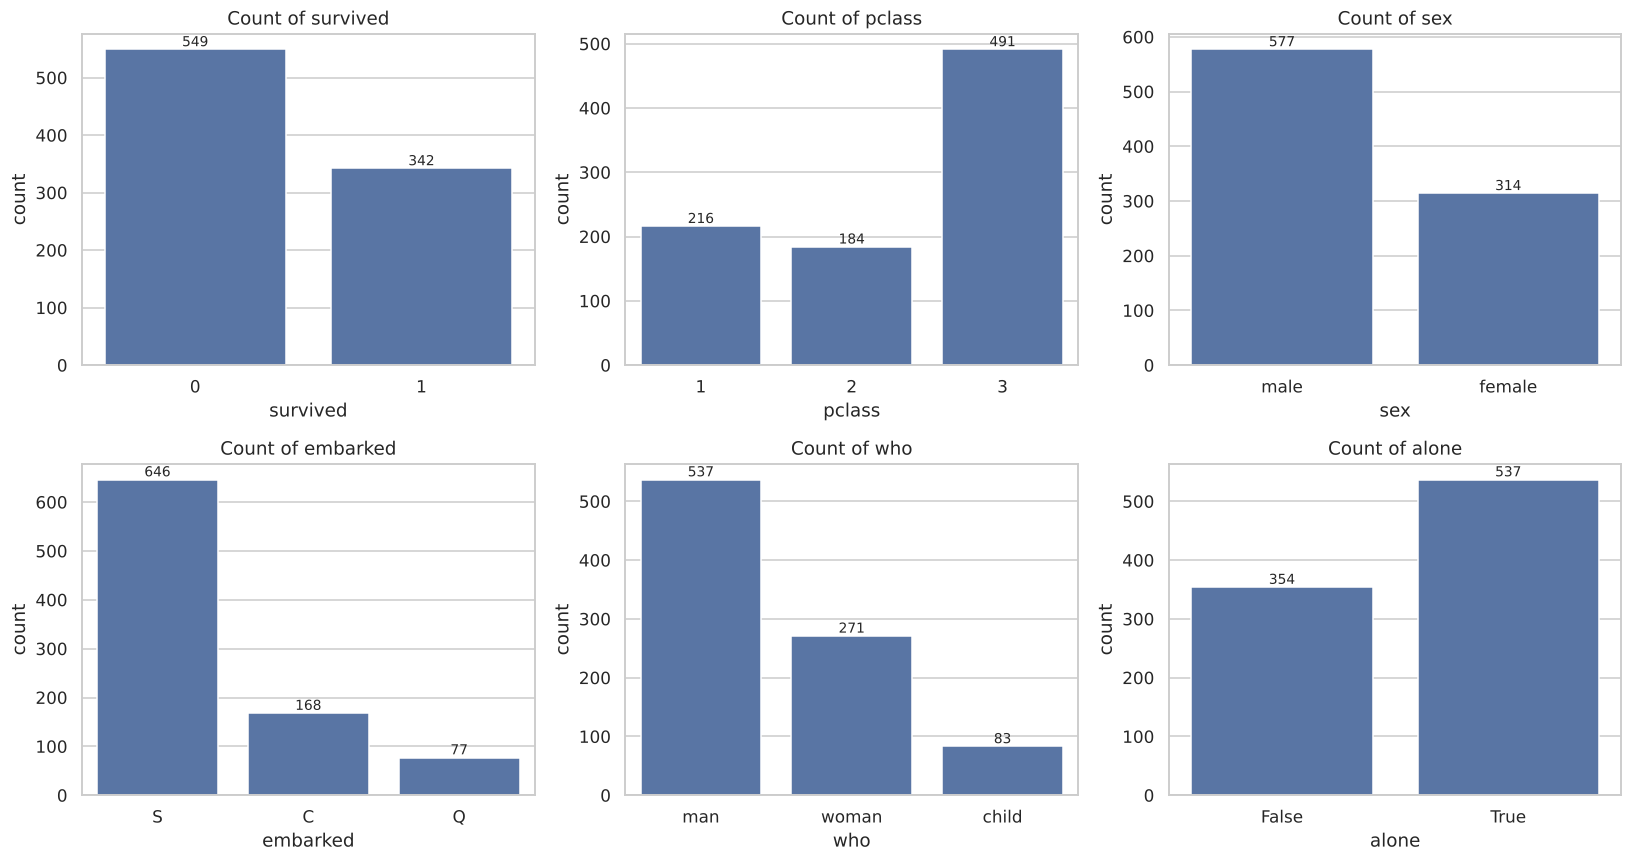

In [9]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
for ax,col in zip(axes.flat,['survived','pclass','sex','embarked','who','alone']):
    sns.countplot(x=col, data=data, ax=ax)
    ax.set_title(f'Count of {col}')
    for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.savefig('images/03_countplots.png'); plt.show()

**Observations**
- Majority did not survive (549 vs 342). Males (65%) and 3rd-class passengers (55%) dominate the manifest.
- Southampton was the main port of embarkation; most passengers were adult men (`who = man`: 537).

## 5. Bivariate Analysis — Relationship with Survival

### 5.1 Survival rate by categorical features (bar plots)

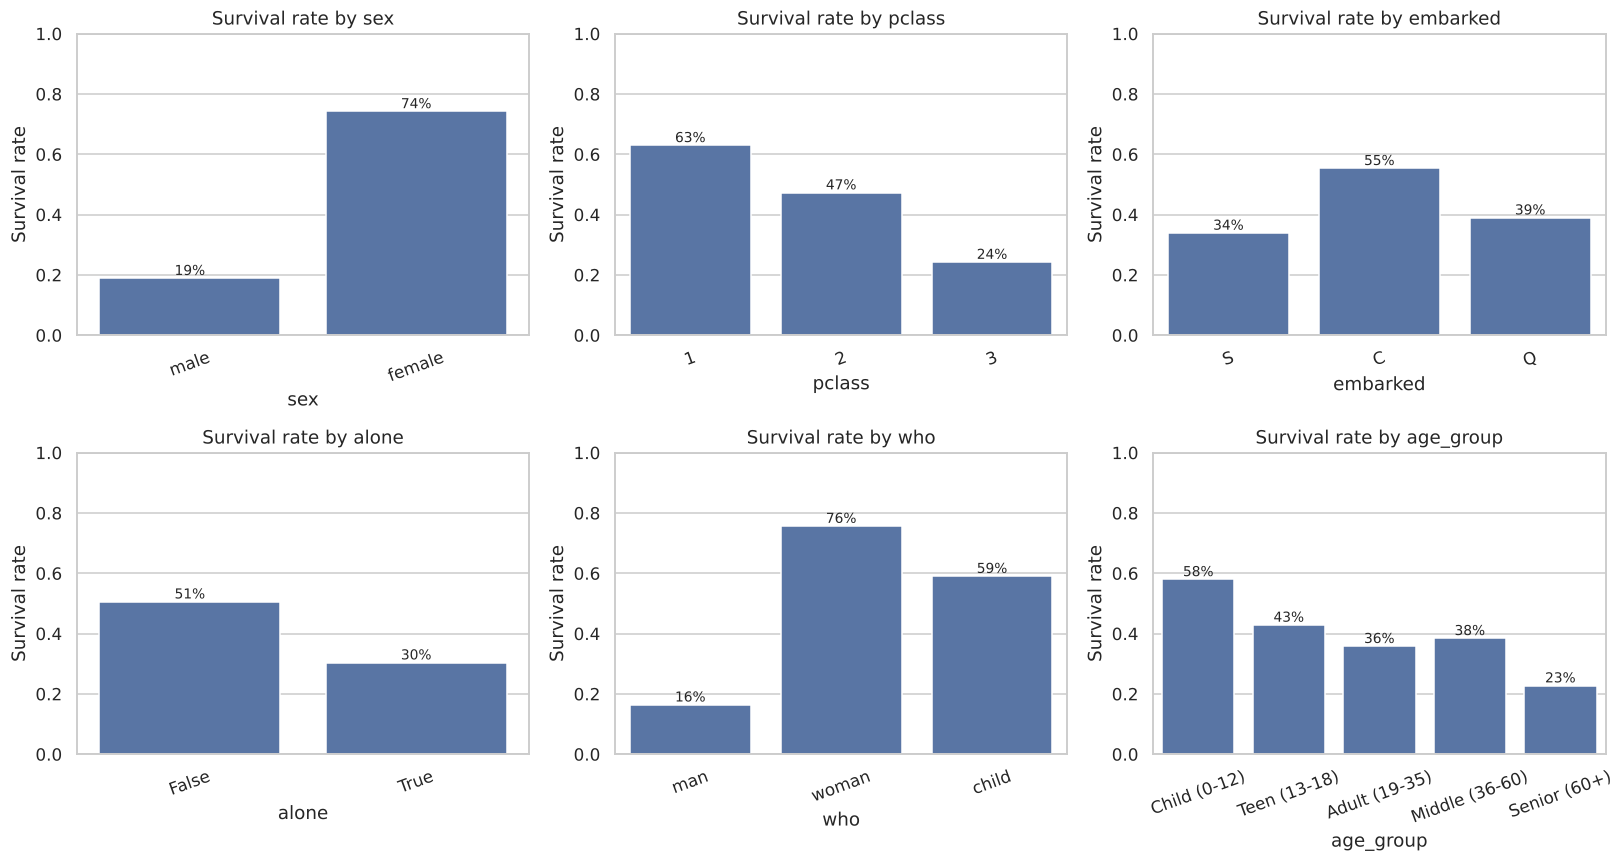

In [10]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
for ax,col in zip(axes.flat,['sex','pclass','embarked','alone','who','age_group']):
    sns.barplot(x=col, y='survived', data=data, ax=ax, errorbar=None)
    ax.set_title(f'Survival rate by {col}'); ax.set_ylim(0,1); ax.set_ylabel('Survival rate')
    ax.tick_params(axis='x', rotation=20)
    for p in ax.patches: ax.annotate(f'{p.get_height():.0%}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.savefig('images/04_survival_rates.png'); plt.show()

**Observations**
- **Sex is the strongest driver:** 74% of women survived vs only 19% of men.
- **Class matters:** 63% (1st) → 47% (2nd) → 24% (3rd).
- **Embarkation:** Cherbourg passengers survived at 55% vs 34% at Southampton — largely because about half of Cherbourg passengers were 1st class (vs ~20% at Southampton).
- **Children (0–12) survived at 58%**; seniors (60+) only 23%. "Women and children first" is clearly visible.
- Solo travellers had lower survival (30%) than those with family (51%).

### 5.2 Boxplots — numeric features vs. survival / class

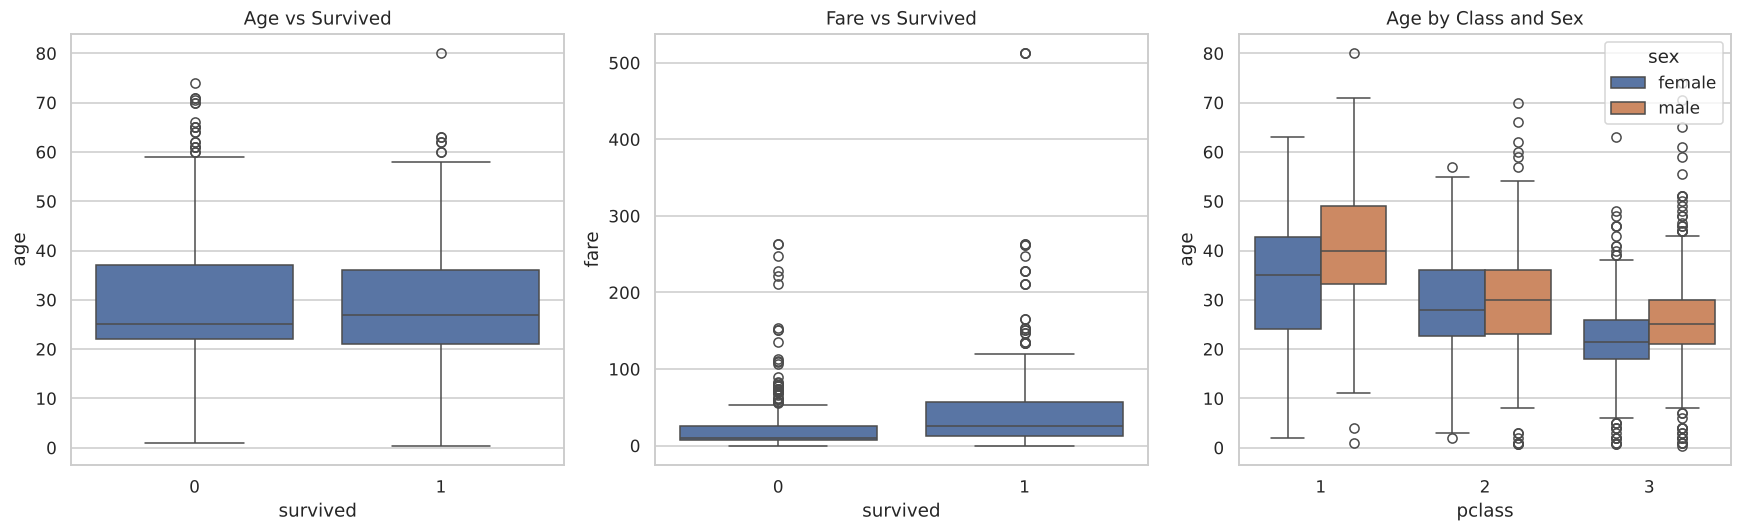

In [11]:
fig, axes = plt.subplots(1,3, figsize=(16,5))
sns.boxplot(x='survived', y='age', data=data, ax=axes[0]); axes[0].set_title('Age vs Survived')
sns.boxplot(x='survived', y='fare', data=data, ax=axes[1]); axes[1].set_title('Fare vs Survived')
sns.boxplot(x='pclass', y='age', hue='sex', data=data, ax=axes[2]); axes[2].set_title('Age by Class and Sex')
plt.tight_layout(); plt.savefig('images/05_boxplots.png'); plt.show()

**Observations**
- Median age is nearly identical for survivors and non-survivors (28) → age alone is a weak predictor; survivors include more children.
- Survivors paid much more: median fare **£26 vs £10.5**.
- Passengers get older as class improves (median age 37 / 29 / 24 for 1st / 2nd / 3rd).

### 5.3 Violin / KDE — age distribution by survival and sex

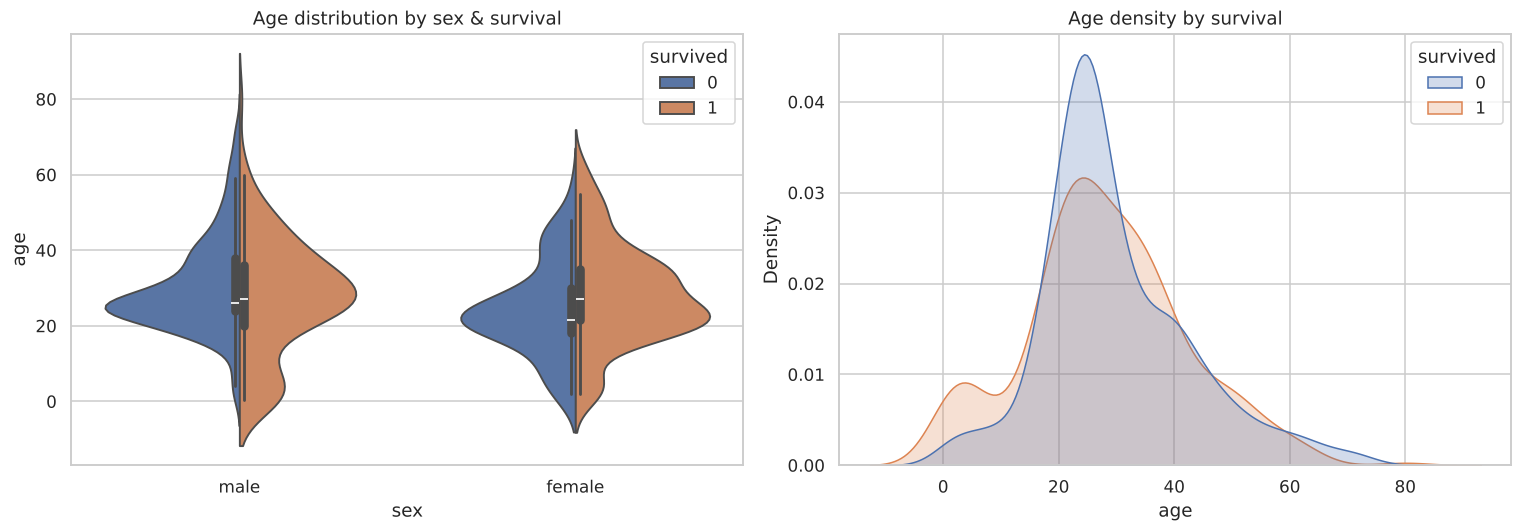

In [12]:
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.violinplot(x='sex', y='age', hue='survived', data=data, split=True, ax=axes[0]); axes[0].set_title('Age distribution by sex & survival')
sns.kdeplot(data=data, x='age', hue='survived', fill=True, common_norm=False, ax=axes[1]); axes[1].set_title('Age density by survival')
plt.tight_layout(); plt.savefig('images/06_violin_kde.png'); plt.show()

**Observations**
- Young boys (under ~10) have a high survival density, unlike adult males.
- The KDE for survivors has an extra bump at ages 0–10; both curves are otherwise very similar.

### 5.4 Scatter plots

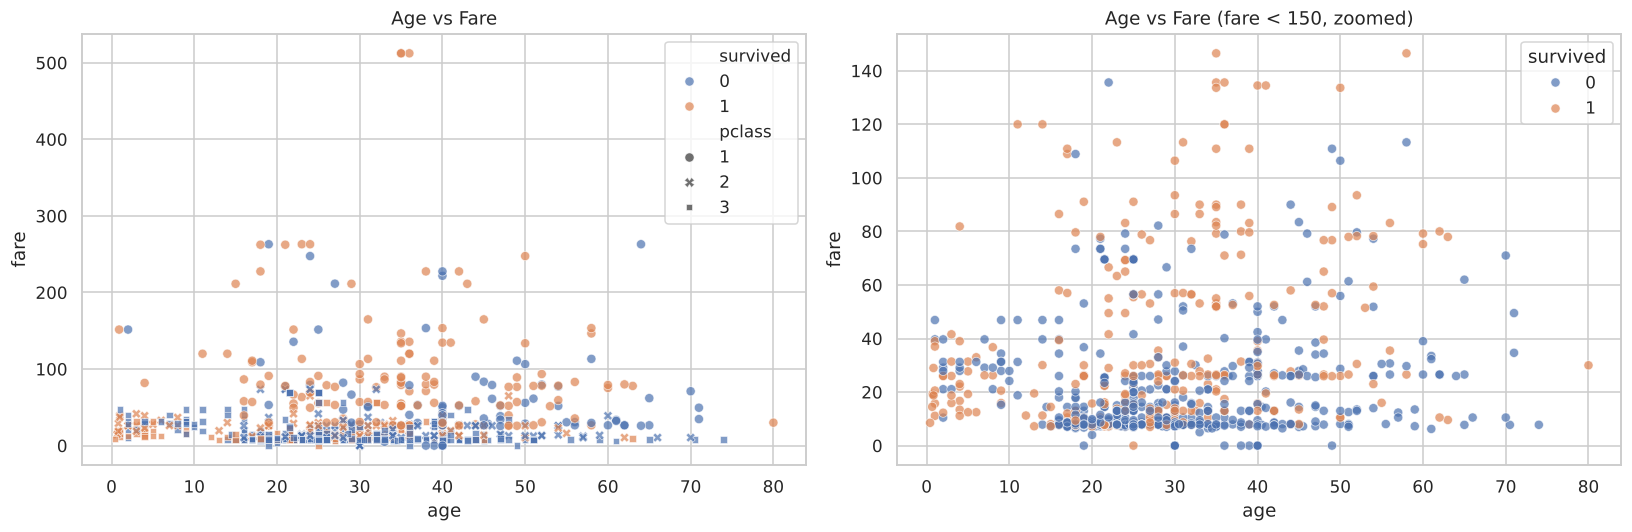

In [13]:
fig, axes = plt.subplots(1,2, figsize=(15,5))
sns.scatterplot(x='age', y='fare', hue='survived', style='pclass', data=data, alpha=.7, ax=axes[0]); axes[0].set_title('Age vs Fare')
sns.scatterplot(x='age', y='fare', hue='survived', data=data[data.fare<150], alpha=.7, ax=axes[1]); axes[1].set_title('Age vs Fare (fare < 150, zoomed)')
plt.tight_layout(); plt.savefig('images/07_scatter.png'); plt.show()

**Observations**
- There is no linear relationship between age and fare (r ≈ 0.10), but the highest fares (> £200, all 1st class) show a 70% survival rate (14 of 20).
- The low-fare region is dominated by non-survivors.

## 6. Multivariate Analysis

### 6.1 Correlation heatmap

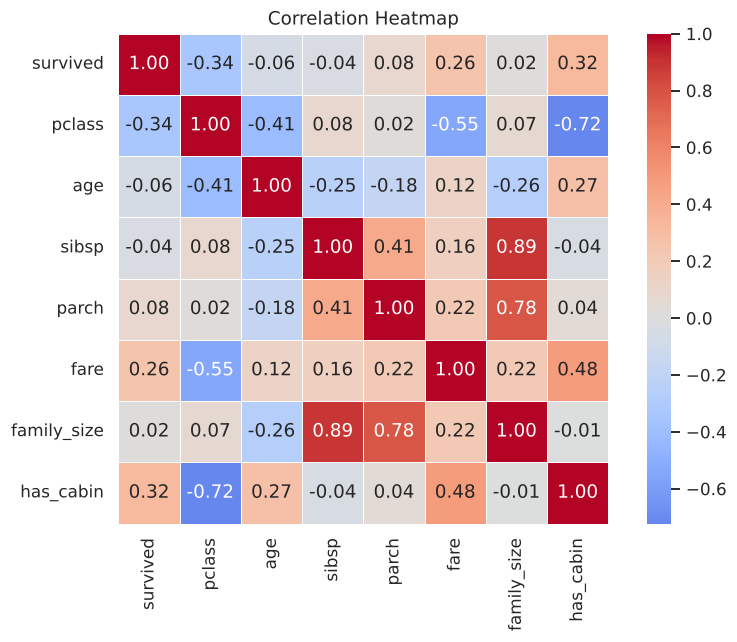

In [14]:
num = data[['survived','pclass','age','sibsp','parch','fare','family_size','has_cabin']]
plt.figure(figsize=(8,6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=.5)
plt.title('Correlation Heatmap'); plt.tight_layout(); plt.savefig('images/08_heatmap.png'); plt.show()

**Observations**
- `survived` correlates most with `has_cabin` (+0.32), `fare` (+0.26) and `pclass` (−0.34).
- `pclass` ↔ `fare` is strongly negative (−0.55) – a **multicollinearity** warning if both are used in a linear model.
- `sibsp` ↔ `parch` (0.41) and `family_size` are mechanically related (family_size = sibsp + parch + 1).

### 6.2 Pairplot

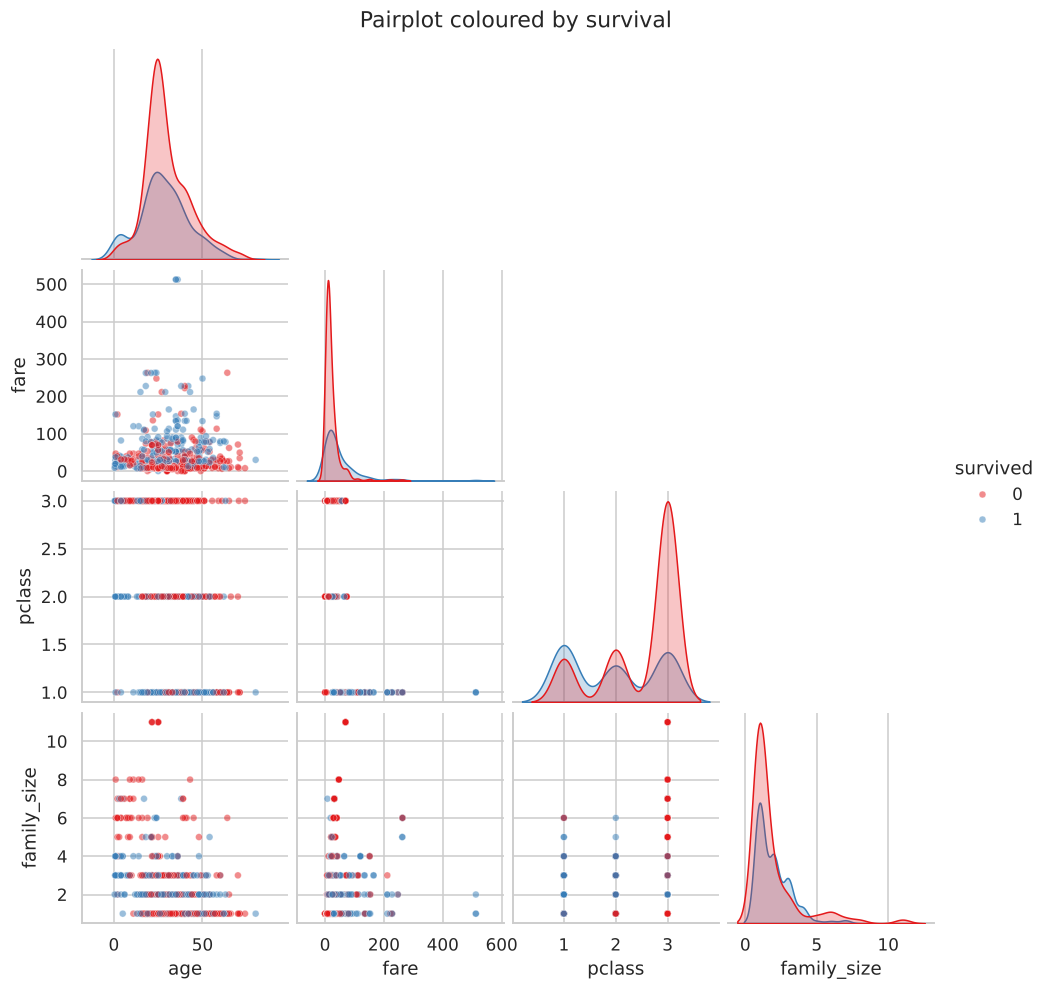

In [15]:
g = sns.pairplot(data[['survived','age','fare','pclass','family_size']], hue='survived', corner=True, palette='Set1', plot_kws={'alpha':.5,'s':20}, height=2.2)
g.fig.suptitle('Pairplot coloured by survival', y=1.02)
g.savefig('images/09_pairplot.png'); plt.show()

**Observations**
- Survivors (blue) cluster in low `pclass` values (1st class) and higher fares.
- Fare vs. other variables shows heavy right tail; no clear linear pattern between pairs, signalling that relationships are mostly categorical/non-linear.

### 6.3 Class × Sex × Survival

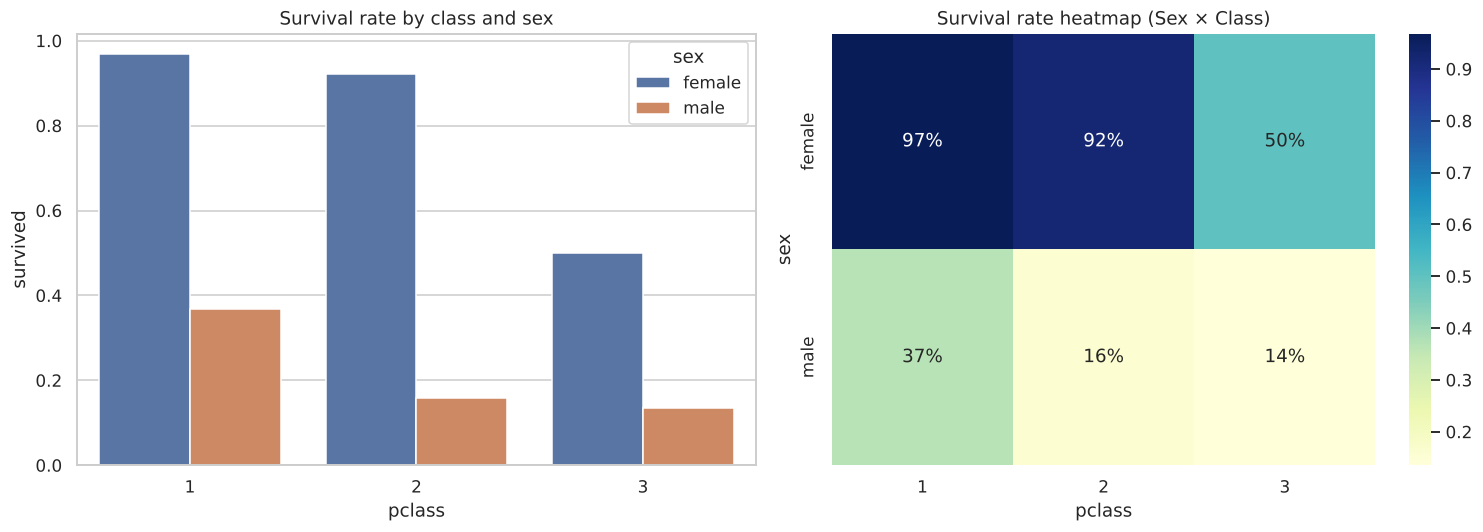

pclass,1,2,3
sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


In [16]:
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.barplot(x='pclass', y='survived', hue='sex', data=data, errorbar=None, ax=axes[0]); axes[0].set_title('Survival rate by class and sex')
pivot = data.pivot_table(values='survived', index='sex', columns='pclass', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='YlGnBu', ax=axes[1]); axes[1].set_title('Survival rate heatmap (Sex × Class)')
plt.tight_layout(); plt.savefig('images/10_class_sex.png'); plt.show()
pivot.round(3)

**Observations**
- 1st-class women: **97%** survived; 2nd-class women: 92%; 3rd-class women only 50%.
- Males: 37% (1st), 16% (2nd), 13.5% (3rd). Being a 3rd-class male was the worst combination.
- Class and sex have an **interaction effect** – the class advantage is much larger for women.

### 6.4 Family size & cabin

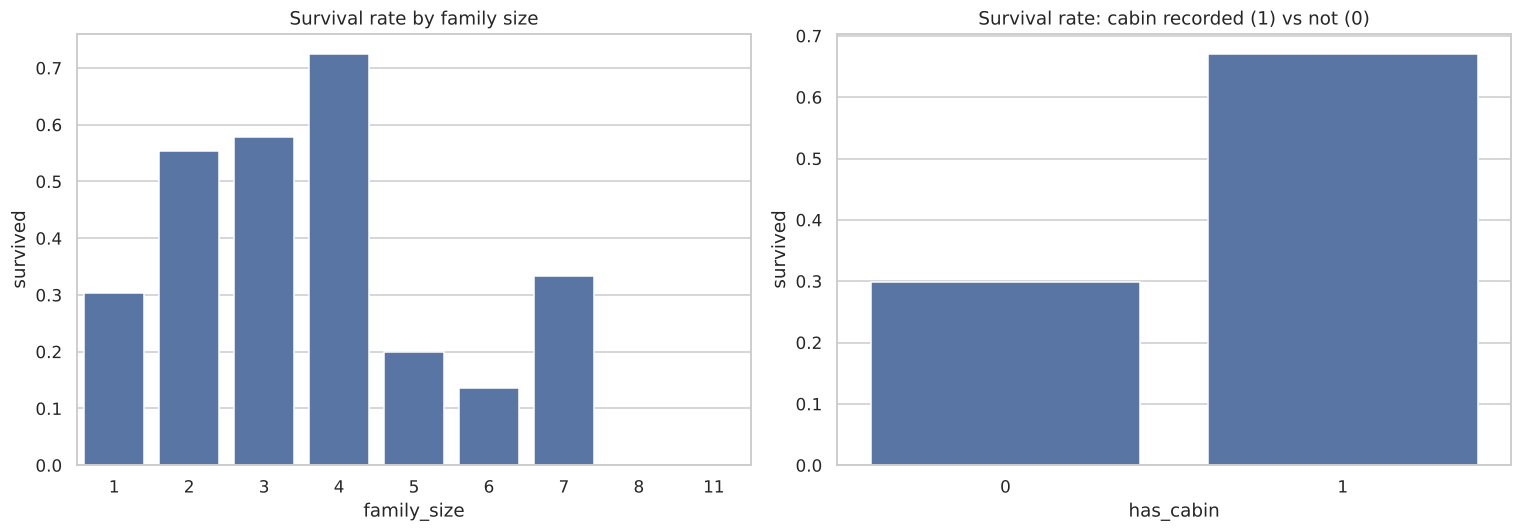

In [17]:
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.barplot(x='family_size', y='survived', data=data, errorbar=None, ax=axes[0]); axes[0].set_title('Survival rate by family size')
sns.barplot(x='has_cabin', y='survived', data=data, errorbar=None, ax=axes[1]); axes[1].set_title('Survival rate: cabin recorded (1) vs not (0)')
plt.tight_layout(); plt.savefig('images/11_family_cabin.png'); plt.show()

**Observations**
- Survival peaks for small families (2–4 people: 55–72%) and drops sharply for solo travellers (30%) and large families of 5+ (≤ 33%).
- Passengers with a recorded cabin survived at **67%** vs **30%** without one (proxy for wealth/location on ship).

## 7. Outliers & Skewness

Fare IQR upper fence: 65.6 | outliers: 116 | max: 512.3
Skew before log: 4.79 | after log1p: 0.39


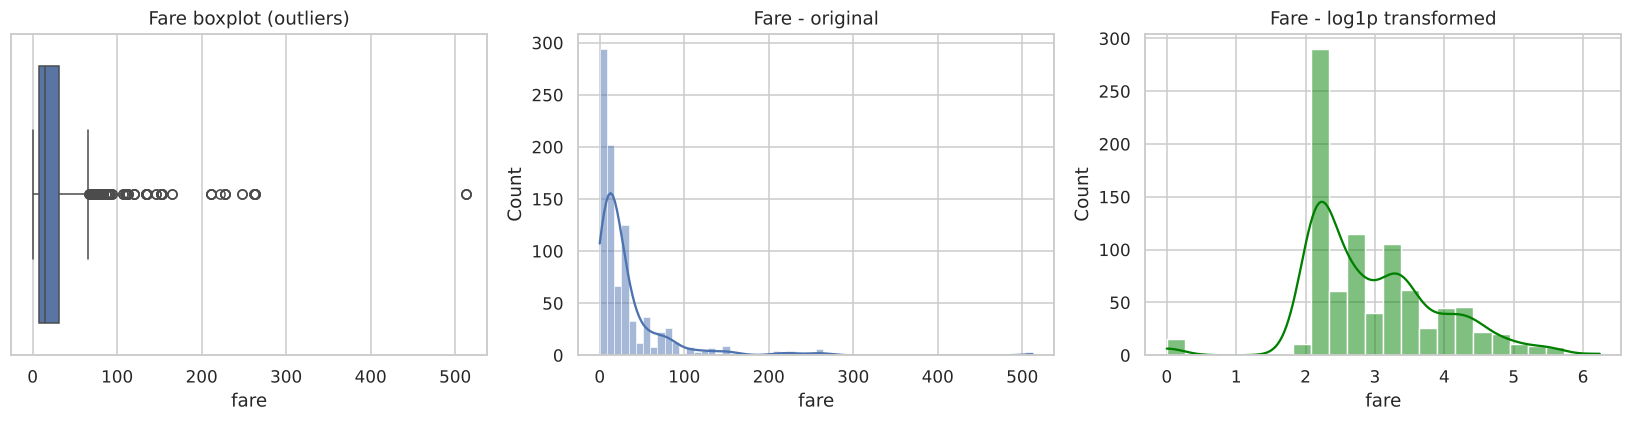

,pclass,sex,age,fare,survived
258,1,female,35.0,512.3292,1
679,1,male,36.0,512.3292,1
737,1,male,35.0,512.3292,1


In [18]:
Q1,Q3 = data.fare.quantile([.25,.75]); IQR=Q3-Q1
upper = Q3+1.5*IQR
print(f'Fare IQR upper fence: {upper:.1f} | outliers: {(data.fare>upper).sum()} | max: {data.fare.max():.1f}')
print('Skew before log:', round(data.fare.skew(),2), '| after log1p:', round(np.log1p(data.fare).skew(),2))

fig, axes = plt.subplots(1,3, figsize=(15,4))
sns.boxplot(x=data.fare, ax=axes[0]); axes[0].set_title('Fare boxplot (outliers)')
sns.histplot(data.fare, kde=True, ax=axes[1]); axes[1].set_title('Fare - original')
sns.histplot(np.log1p(data.fare), kde=True, ax=axes[2], color='green'); axes[2].set_title('Fare - log1p transformed')
plt.tight_layout(); plt.savefig('images/12_outliers_skew.png'); plt.show()
data[data.fare>500][['pclass','sex','age','fare','survived']]

**Observations**
- 116 passengers (13%) exceed the IQR upper fence (£65.6). Three passengers paid £512.33 — all 1st class and all survived; they are genuine (not errors) so they are kept.
- A **log1p transform reduces fare skew from 4.8 to 0.4**, giving a near-symmetric distribution suitable for modelling.
- 15 passengers have `fare = 0` (likely crew/staff or missing data) — an anomaly worth flagging.

## 8. Summary of Findings
| # | Finding | Evidence |
|---|---|---|
| 1 | Overall survival was 38.4% | 342 / 891 |
| 2 | **Sex** is the strongest predictor | Women 74% vs men 19% |
| 3 | **Passenger class** strongly matters | 63% / 47% / 24% for 1st / 2nd / 3rd |
| 4 | Class × sex interaction | 1st-class women 97% vs 3rd-class men 13.5% |
| 5 | Children had a survival advantage | 58% for ages 0–12; seniors 23% |
| 6 | Higher fare ⇒ higher survival | Median £26 (survived) vs £10.5 (died) |
| 7 | Small families fared best | 2–4 members: 55–72%; solo: 30% |
| 8 | Cabin recorded ⇒ higher survival | 67% vs 30% |
| 9 | Embarkation port effect is confounded by class | Cherbourg 55% vs Southampton 34% |
| 10 | Data quality issues | `deck` 77% missing, `age` 20% missing, fare heavily skewed with outliers, `pclass`–`fare` collinearity |

**Conclusion:** Survival followed a "women & children first" rule combined with a strong socio-economic gradient. Gender, class, fare and family size should be the key features in any predictive model; fare should be log-transformed and age imputed by class/sex.

## 9. Interview Questions — Answers
**1. What is EDA and why is it important?**  
EDA is the process of summarising and visualising a dataset to understand its structure, distributions, relationships, missing values and anomalies *before* modelling. It guides cleaning, feature engineering, model choice and prevents wrong assumptions.

**2. Which plots do you use to check correlation?**  
Correlation heatmap, scatter plot, pairplot, and regression plot (`sns.regplot`/`lmplot`); for categorical vs numeric, box/violin plots; for categorical vs categorical, crosstab heatmaps.

**3. How do you handle skewed data?**  
Apply log / log1p, square-root, Box-Cox or Yeo-Johnson transforms; clip/winsorise outliers; use robust statistics (median, IQR); or use tree-based models that are insensitive to skew. (Here: log1p cut fare skew from 4.8 → 0.4.)

**4. How to detect multicollinearity?**  
Correlation matrix/heatmap (|r| > 0.7–0.8), Variance Inflation Factor (VIF > 5–10), condition number, and unstable/sign-flipping regression coefficients. Fix by dropping/combining features, PCA or regularisation (Ridge/Lasso).

**5. Univariate, bivariate and multivariate analysis?**  
*Univariate*: one variable (histogram, boxplot, value_counts). *Bivariate*: two variables (scatter, bar of survival by sex, correlation). *Multivariate*: three or more together (pairplot, correlation heatmap, class×sex×survival, PCA).

**6. Difference between heatmap and pairplot?**  
A heatmap colour-codes a matrix (e.g., correlation coefficients) – compact, numeric summary of linear relationships. A pairplot is a grid of scatter plots and histograms/KDEs for every variable pair – shows the actual shape, clusters and outliers but gets crowded with many variables.

**7. How do you summarise your insights?**  
State the objective, list the top findings quantitatively (with numbers), link each to a visual, highlight data-quality issues and anomalies, give actionable recommendations/next steps, and keep it concise for a non-technical audience.